# 自然言語処理システムの開発サイクル（文分割・データ分割・計算量）

書籍 第1章「自然言語処理システムのデザイン」（1-4-2 データの分け方、1-4-3 計算量、1-5 開発サイクル）に対応する演習ノートブックです。
CPU のみ・数秒で実行でき、システム設計・運用の基盤となる 3 つのポイントを体験します。

1. **前処理 (1-5-1)**: 素朴な句点文分割が破綻するケース（「モーニング娘。」など）と例外処理
2. **データの分け方 (1-4-2)**: 訓練・開発・テストの役割とハイパーパラメータの選択に使ったデータで最終成績を報告したときの過大評価の実験
3. **計算量の実測（1-4-3, 表 1.1）**: $O(1)$（ハッシュ辞書）vs $O(n)$（線形探索）vs $O(n^2)$（全対比較）の実行時間スケーリング

（※ 半教師あり学習・遠距離教師あり学習については [`ch1_semisupervised.ipynb`](https://colab.research.google.com/github/mamorlis/nlpbook/blob/main/notebooks/ch1_semisupervised.ipynb) を、開発サイクルに基づく文書分類の素性設計アブレーションについては [`ch1_tfidf_baseline.ipynb`](https://colab.research.google.com/github/mamorlis/nlpbook/blob/main/notebooks/ch1_tfidf_baseline.ipynb) を参照してください。）

In [1]:
!curl -fLO https://raw.githubusercontent.com/mamorlis/nlpbook/refs/heads/main/misc/covid-annotation.csv

  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed
  0     0    0     0    0     0      0      0 --:--:-- --:--:-- --:--:--     0

100  532k  100  532k    0     0   955k      0 --:--:-- --:--:-- --:--:--  956k


In [2]:
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline

---

## 1. 前処理：文分割の落とし穴（1-5-1、p.42）

書籍 1-5-1 では、句点「。」だけで単純に文を分割すると**「モーニング娘。」のように句点が固有名詞に含まれている場合や、括弧・小数点・略語**で誤分割してしまうことが指摘されています。

In [3]:
def naive_split_sentences(text):
    return [s for s in text.split("。") if s.strip()]

def protected_split_sentences(text):
    # 固有名詞中の句点や括弧内の句点を保護して文分割する簡易例
    # （実運用では 3-2 の形態素解析を併用するのが確実です）
    protected_terms = ["モーニング娘。"]
    masked = text
    for i, term in enumerate(protected_terms):
        masked = masked.replace(term, f"__PROT_{i}__")

    # 括弧外の句点のみで分割
    out, buf, depth = [], [], 0
    for ch in masked:
        buf.append(ch)
        if ch in "（「(":
            depth += 1
        elif ch in "」）)" and depth > 0:
            depth -= 1
        elif ch == "。" and depth == 0:
            out.append("".join(buf).strip())
            buf = []
    if "".join(buf).strip():
        out.append("".join(buf).strip())

    restored = []
    for s in out:
        for i, term in enumerate(protected_terms):
            s = s.replace(f"__PROT_{i}__", term)
        restored.append(s)
    return restored

sample_text = (
    "彼女はモーニング娘。のファンです。"
    "ライブの感想をメモ（会場はとても熱気があった。音響も良い。）にまとめた。"
    "隣の家に住んでいるネコが寝込んだ。"
)

print("=== 素朴な句点分割（text.split('。')） ===")
for i, s in enumerate(naive_split_sentences(sample_text), 1):
    print(f"  {i}: {s}")

print("\n=== 固有名詞・括弧を考慮した文分割 ===")
for i, s in enumerate(protected_split_sentences(sample_text), 1):
    print(f"  {i}: {s}")

=== 素朴な句点分割（text.split('。')） ===
  1: 彼女はモーニング娘
  2: のファンです
  3: ライブの感想をメモ（会場はとても熱気があった
  4: 音響も良い
  5: ）にまとめた
  6: 隣の家に住んでいるネコが寝込んだ

=== 固有名詞・括弧を考慮した文分割 ===
  1: 彼女はモーニング娘。のファンです。
  2: ライブの感想をメモ（会場はとても熱気があった。音響も良い。）にまとめた。
  3: 隣の家に住んでいるネコが寝込んだ。


---

## 2. データの分け方：開発データ vs テストデータの役割（1-4-2、p.36〜37）

訓練データでモデルの重みを学習し、**開発データ (validation / dev data) でハイパーパラメータを選び、最終評価には開発時に一切触れていないテストデータ (test data) を使う**必要があります。
もし「小さな評価用データで一番スコアが高かった設定」をそのまま最終成績として報告してしまうと、見かけの精度が過大評価されます（**評価データへの過適合**）。`covid-annotation.csv`（1,000件）で確認してみましょう。

In [4]:
df = pd.read_csv("covid-annotation.csv")
df["y"] = (df["ラベル"] == True).astype(int)

# 訓練(160件) / 小規模な検証・選択用(60件) / 未知の最終テスト(780件) に分割
train_df, rest_df = train_test_split(df, train_size=160, stratify=df["y"], random_state=7)
select_df, final_test_df = train_test_split(rest_df, train_size=60, stratify=rest_df["y"], random_state=7)

candidates = [
    (ngram, min_df, C)
    for ngram in [(1, 1), (1, 2), (1, 3), (2, 3)]
    for min_df in [1, 2, 3]
    for C in [0.1, 0.5, 1.0, 3.0, 10.0, 30.0]
]

results = []
for ngram, min_df, C in candidates:
    pipe = make_pipeline(
        TfidfVectorizer(analyzer="char_wb", ngram_range=ngram, min_df=min_df),
        LogisticRegression(C=C, max_iter=1000),
    )
    pipe.fit(train_df["文書"], train_df["y"])
    acc_sel = accuracy_score(select_df["y"], pipe.predict(select_df["文書"]))
    acc_final = accuracy_score(final_test_df["y"], pipe.predict(final_test_df["文書"]))
    results.append({
        "ngram": ngram, "min_df": min_df, "C": C,
        "選択用データの正解率": acc_sel,
        "未知テスト(780件)の正解率": acc_final,
    })

res_df = pd.DataFrame(results).sort_values("選択用データの正解率", ascending=False)
print(f"探索した設定数: {len(res_df)} 通り")
display(res_df.head(5))

top1 = res_df.iloc[0]
print(
    f"選択用データ(60件)で最良だった設定: ngram={top1['ngram']}, min_df={top1['min_df']}, C={top1['C']}\n"
    f"  選択用データで見積もった正解率 : {top1['選択用データの正解率']:.3f} \n"
    f"  テストデータ(780件)での正解率 : {top1['未知テスト(780件)の正解率']:.3f}"
)

探索した設定数: 72 通り


,ngram,min_df,C,選択用データの正解率,未知テスト(780件)の正解率
58,"(2, 3)",1,10.0,0.950000,0.907692
59,"(2, 3)",1,30.0,0.950000,0.914103
40,"(1, 3)",1,10.0,0.933333,0.893590
41,"(1, 3)",1,30.0,0.933333,0.906410
56,"(2, 3)",1,1.0,0.933333,0.858974


選択用データ(60件)で最良だった設定: ngram=(2, 3), min_df=1, C=10.0
  選択用データで見積もった正解率 : 0.950 
  テストデータ(780件)での正解率 : 0.908


この実験では、選択用データ（60件）で最も正解率が高かった設定を選びます。その設定の正解率を、設定の選択に使った60件と、選択に使わなかった780件で比べてください。比較のため、このセルでは全候補のテスト正解率も計算しています。実際の開発では、開発データで設定を決めてから、選んだ設定だけをテストデータで評価します。テストの結果を見て設定をさらに変更する場合は、新たに独立したテストデータを用意します。

---

## 3. 計算量の実測：$O(1)$ vs $O(n)$ vs $O(n^2)$（1-4-3、表 1.1、p.37〜39）

書籍 1-4-3 では、処理時間を見積もる概念として **時間計算量（ビッグ・オー記法）** が解説されています。
データ数 $n$ を倍々 ($400 \to 800 \to 1600 \to 3200 \to 6400$) に増やしたとき、次の 3 つのアルゴリズムの実行時間がどう伸びるか実測してみましょう。

- **$O(1)$**: Python の `set`（ハッシュ表）による要素の有無の確認（平均）（300 クエリ検索）
- **$O(n)$**: Python の `list` による線形探索（300 クエリ検索）
- **$O(n^2)$**: 文書集合内の全ペア総当たり類似度計算（Transformer の自己注意や全対比較相当）

,n,O(1) set検索 [ms],O(n) list検索 [ms],O(n^2) 全ペア積 [ms]
0,400,0.020,1.150,4.113
1,800,0.022,2.386,13.105
2,1600,0.020,4.525,26.485
3,3200,0.264,12.604,42.582
4,6400,0.380,20.025,69.762


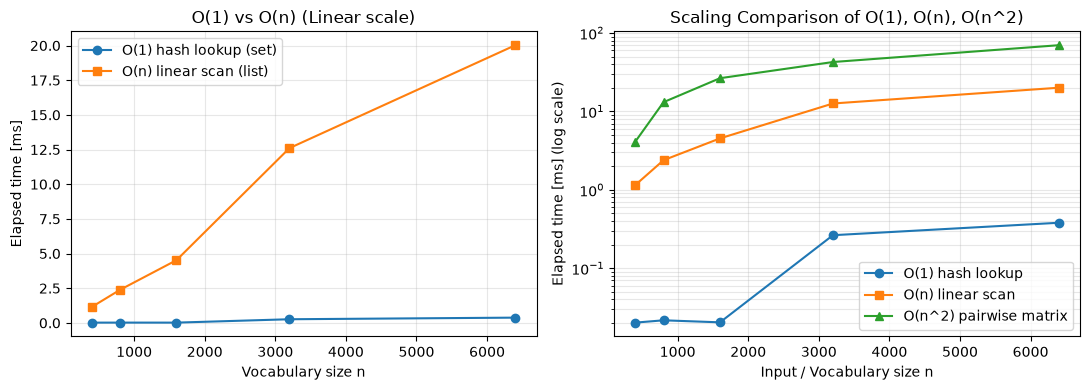

In [5]:
sizes = [400, 800, 1600, 3200, 6400]
rng = np.random.default_rng(0)
# BLAS 初期化の初回オーバーヘッドを除外するためのウォームアップ
_ = rng.random((256, 32), dtype=np.float32) @ rng.random((32, 256), dtype=np.float32)

bench = []
for n in sizes:
    vocab_list = [f"term_{i}" for i in range(n)]
    vocab_set = set(vocab_list)
    # 先頭・中央・末尾・未登録語を混ぜて、n に比例した探索距離になるクエリを作る
    hit_queries = [vocab_list[i] for i in np.linspace(0, n - 1, 150, dtype=int)]
    miss_queries = [f"missing_{i}" for i in range(150)]
    queries = hit_queries + miss_queries

    # O(1): ハッシュ検索 × 300クエリ
    t0 = time.perf_counter()
    _ = sum(q in vocab_set for q in queries)
    t_o1 = (time.perf_counter() - t0) * 1000

    # O(n): リスト線形探索 × 300クエリ
    t0 = time.perf_counter()
    _ = sum(q in vocab_list for q in queries)
    t_on = (time.perf_counter() - t0) * 1000

    # O(n^2): n × n の内積計算（全ペア比較）
    vecs = rng.random((n, 32), dtype=np.float32)
    t0 = time.perf_counter()
    _ = vecs @ vecs.T
    t_on2 = (time.perf_counter() - t0) * 1000

    bench.append({
        "n": n,
        "O(1) set検索 [ms]": t_o1,
        "O(n) list検索 [ms]": t_on,
        "O(n^2) 全ペア積 [ms]": t_on2,
    })

df_bench = pd.DataFrame(bench)
display(df_bench.round(3))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(df_bench["n"], df_bench["O(1) set検索 [ms]"], marker="o", label="O(1) hash lookup (set)")
axes[0].plot(df_bench["n"], df_bench["O(n) list検索 [ms]"], marker="s", label="O(n) linear scan (list)")
axes[0].set_xlabel("Vocabulary size n")
axes[0].set_ylabel("Elapsed time [ms]")
axes[0].set_title("O(1) vs O(n) (Linear scale)")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(df_bench["n"], df_bench["O(1) set検索 [ms]"], marker="o", label="O(1) hash lookup")
axes[1].plot(df_bench["n"], df_bench["O(n) list検索 [ms]"], marker="s", label="O(n) linear scan")
axes[1].plot(df_bench["n"], df_bench["O(n^2) 全ペア積 [ms]"], marker="^", label="O(n^2) pairwise matrix")
axes[1].set_yscale("log")
axes[1].set_xlabel("Input / Vocabulary size n")
axes[1].set_ylabel("Elapsed time [ms] (log scale)")
axes[1].set_title("Scaling Comparison of O(1), O(n), O(n^2)")
axes[1].legend()
axes[1].grid(alpha=0.3, which="both")

plt.tight_layout()
plt.show()

### まとめと次のステップ

- **前処理（1-5-1）**: 句点「。」の単純分割は固有名詞や括弧内の文で誤分割を起こすため、例外処理や形態素解析との併用が重要です。
- **データ分割（1-4-2）**: 小さな選択用データでハイパーパラメータを選び続けると、選択用データの正解率が未知テストデータの正解率より過大に見積もられます。開発データと最終テストデータを厳密に分離してください。
- **計算量（1-4-3）**: 語彙・データ規模 $n$ が大きくなるほど、$O(1)$ ハッシュ探索と $O(n)$ 線形探索・$O(n^2)$ 全対計算の差は急激に拡大します。

関連する演習として、少ないシードや知識ベースからデータを拡張・構築する [`ch1_semisupervised.ipynb`](https://colab.research.google.com/github/mamorlis/nlpbook/blob/main/notebooks/ch1_semisupervised.ipynb) や、開発データのみを用いて素性改良のサイクルを回す [`ch1_tfidf_baseline.ipynb`](https://colab.research.google.com/github/mamorlis/nlpbook/blob/main/notebooks/ch1_tfidf_baseline.ipynb) もあわせて参照してください。